In [2]:
import pandas as pd
import numpy as np
import networkx as nx
from torch_geometric.datasets import TUDataset
from diversity_curves.utils import graph_processing_torch

dataset_names = ["ENZYMES", "PROTEINS"]

In [4]:
all_y=[]
for c in dataset_names:
    root = "./../data/TUDataset"
    #dataset_name = "MUTAG"
    pyg_dataset = TUDataset(root=root, name=c)

    van_graph_list = graph_processing_torch(pyg_dataset)
    lables = [data.y.item() for data in pyg_dataset]
    all_y.extend(lables)

Processing...
Done!
Processing...
Done!


In [6]:
dataset_label =[]
df_all = pd.DataFrame()
for d in dataset_names:
    pyg_dataset = TUDataset(root=root, name=d)

    van_graph_list = graph_processing_torch(pyg_dataset)
    #lables = [d+"_"+str(data.y.item()) for data in pyg_dataset]
    lables = [d+"_"+str(data.y.item()) for data in pyg_dataset]
    #all_y.extend(lables)
    #try:
    df = pd.read_csv(f"./results/{d}/mag_funs_shortest_path_distance.csv", index_col=0)
    dataset_label.extend([d]*len(df))
    df["dataset"] = d
    df["class"] = lables
    df_all = pd.concat([df_all, df], ignore_index=True)

In [7]:
#num_cols = df_all.select_dtypes(include=[np.number]).columns
num_cols = [str(i) for i in range(1, 91)]
df_all = df_all[num_cols+["dataset", "class"]]

In [8]:
# Linear interpolation per column for NaN entries (numeric columns only)
df_all_copy = df_all.copy()
num_cols = df_all_copy.select_dtypes(include=[np.number]).columns
df_all_copy[num_cols] = df_all_copy[num_cols].interpolate(method="linear", axis=0, limit_direction="both")

In [11]:
df_long = (
    df_all_copy
    #.reset_index(names="graph_index")
    .reset_index()
    .rename(columns={"index": "graph_index"})
    .melt(
        id_vars=["graph_index", "dataset", "class"],
        value_vars=num_cols,
        var_name="n_nodes",
        value_name="value"
    )
)

df_long["n_nodes"] = df_long["n_nodes"].astype(int)
df_long = df_long[df_long.n_nodes < 35]

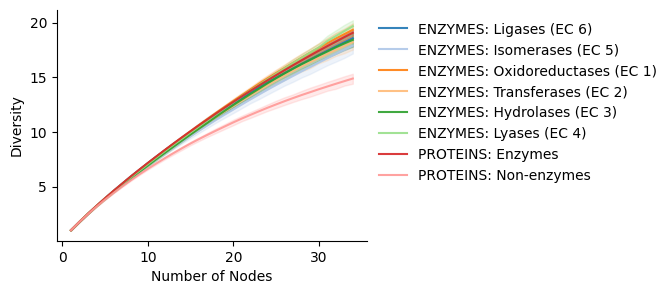

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
df_long2 = df_long[df_long.n_nodes < 35]
dict_rename = {"PROTEINS_0": "PROTEINS: Enzymes", "PROTEINS_1": "PROTEINS: Non-enzymes"}

names=["Oxidoreductases (EC 1)", "Transferases (EC 2)", "Hydrolases (EC 3)", "Lyases (EC 4)", "Isomerases (EC 5)", "Ligases (EC 6)"]

for r in range(6):
    dict_rename[f"ENZYMES_{r}"]= "ENZYMES: " + names[r]
df_long2["class"] = df_long2["class"].map(dict_rename)
plt.figure(figsize=(4,3))
sns.lineplot(data=df_long2[(df_long2.dataset=="ENZYMES") | (df_long2.dataset=="PROTEINS")], x="n_nodes", y="value", hue="class", palette="tab20", alpha=0.9)
sns.despine()
plt.legend(bbox_to_anchor=(1, 1), frameon=False)
sns.despine()
plt.xlabel("Number of Nodes")
plt.ylabel("Diversity")
plt.grid(False)
plt.savefig("./results/tu_data_curves_classes.pdf", bbox_inches='tight')
plt.show()

In [13]:
enzymes = df_all_copy[(df_all_copy.dataset=="ENZYMES") | (df_all_copy.dataset=="PROTEINS")]
proteins = df_all_copy[(df_all_copy.dataset=="PROTEINS")]

In [14]:
dict_rename2 = {"PROTEINS_0": "Enzymes", "PROTEINS_1": "PROTEINS: Non-enzymes"}

for r in range(6):
    dict_rename2[f"ENZYMES_{r}"]= "Enzymes"

In [15]:
enzymes["enzyme"] = ["enzyme" if e else "protein" for e in enzymes["class"] != "PROTEINS_1"]

In [16]:
np.random.seed(42)
class_names = df_all_copy["class"].unique()
test_results = np.zeros((len(class_names), len(class_names)))
test_results_stats = np.zeros((len(class_names), len(class_names)))
for i, dataset_name in enumerate(class_names):
    for j, dataset_name2 in enumerate(class_names):
        if j<=i:
            data1 = df_all_copy[df_all_copy["class"] == dataset_name].drop(columns=["class", "dataset"])
            data2 = df_all_copy[df_all_copy["class"] == dataset_name2].drop(columns=["class", "dataset"])

            mean1 = data1.values.mean(axis=0)
            mean2 = data2.values.mean(axis=0)
            obs_diff = np.linalg.norm((mean1 - mean2))
            combined = np.concatenate([data1.values, data2.values], axis=0)

            perm_diffs = []
            for perm in range(1000):
                perm_data = combined[np.random.permutation(combined.shape[0])]
                perm_data1 = perm_data[:data1.shape[0], :]
                perm_data2 = perm_data[data1.shape[0]:, :]

                mean1_perm = perm_data1.mean(axis=0)
                mean2_perm = perm_data2.mean(axis=0)
                perm_diff = np.linalg.norm((mean1_perm - mean2_perm))
                perm_diffs.append(perm_diff)

            stat = (obs_diff-np.mean(perm_diffs))/np.std(perm_diffs)
            perm_stats = np.array(perm_diffs)
            p_value = (np.sum(perm_stats >= obs_diff)+1)/(len(perm_stats)+1)

            test_results[i, j] = p_value
            test_results_stats[i, j] = stat

test_results = test_results + test_results.T - np.diag(test_results.diagonal())
test_results_stats = test_results_stats + test_results_stats.T - np.diag(test_results_stats.diagonal())

In [17]:
test_results_df = pd.DataFrame(test_results, index=class_names, columns=class_names)
test_results_stats_df = pd.DataFrame(test_results_stats, index=class_names, columns=class_names)

In [18]:
test_results_df_sub = test_results_df.iloc[:8,:]
test_results_df_sub = test_results_df_sub.iloc[:,:8]
new_index = test_results_df_sub.index.map(dict_rename)
test_results_df_sub.index = new_index
test_results_df_sub.columns = new_index

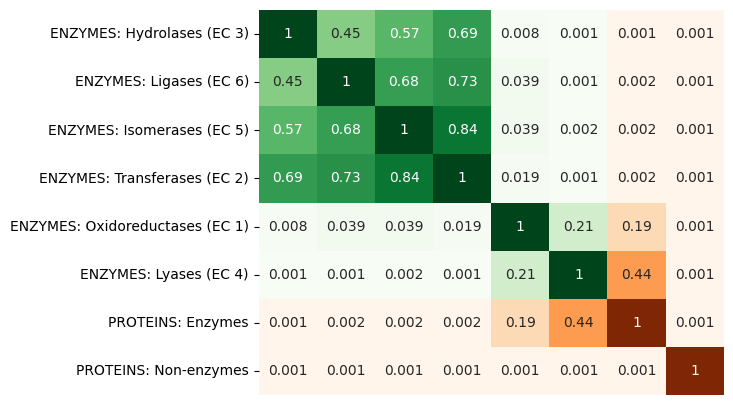

In [ ]:
order = ["ENZYMES: Hydrolases (EC 3)",
        "ENZYMES: Ligases (EC 6)",
         "ENZYMES: Isomerases (EC 5)",
         "ENZYMES: Transferases (EC 2)",
         "ENZYMES: Oxidoreductases (EC 1)",
         "ENZYMES: Lyases (EC 4)",
         "PROTEINS: Enzymes", 
         "PROTEINS: Non-enzymes"]
test_results_df_sub_plot = test_results_df_sub.loc[order,order]
plt.figure(figsize=(6,5))

mask_main = np.zeros_like(test_results_df_sub_plot, dtype=bool)
mask_main[-2:, :] = True
mask_main[:, -2:] = True  

mask_last = ~mask_main  
sns.heatmap(test_results_df_sub_plot, mask=mask_main, cmap="Greens", cbar=False, annot=True)

sns.heatmap(test_results_df_sub_plot, mask=mask_last, cmap="Oranges", cbar=False, annot=True)

plt.xticks([])
n_rows = test_results_df_sub_plot.shape[0]
x_pos = -4

plt.savefig("./results/tu_data_perm_test_classes.pdf", bbox_inches='tight')
plt.show()